### 1. Dataset and Preprocessing
* **Data Sources:** Uses feature-engineered data from the CICIDS2017 and UNSW-NB15 datasets for binary classification (separating normal traffic from attacks) with clean, complete data.
* **Class Imbalance:** Managed using `class_weight='balanced_subsample'` for Random Forest and `scale_pos_weight` for XGBoost.

---

### 2. Baseline Model Performance
* Both default Random Forest and XGBoost models achieved near-perfect accuracy ($\approx 99.91\%$) and a 1.0 ROC-AUC score, maintaining very low false positive and false negative rates.

---

### 3. Hyperparameter Tuning
* **Method:** Applied `RandomizedSearchCV` with 3-fold Stratified Cross-Validation to improve generalization and prevent overfitting.
* **Optimization:** Focused on the **F1-Score** to balance precision and recall. Large training datasets exceeding 200,000 rows were subsampled for faster processing.
* **Export:** Tuning metrics were automatically saved to the `../results/` directory for reporting.

In [12]:
import os
print('Working dir:', os.getcwd())
print('data folder exists:', os.path.exists('../data'))

# find every features.json under the project
root = os.path.abspath('..')
for dirpath, dirs, files in os.walk(root):
    if 'features.json' in files:
        print('FOUND:', dirpath)

Working dir: c:\Users\Shasmeen Aleesa\OneDrive\Desktop\Advanced Network Security\notebooks
data folder exists: True
FOUND: c:\Users\Shasmeen Aleesa\OneDrive\Desktop\Advanced Network Security\data\CICIDS2017_output
FOUND: c:\Users\Shasmeen Aleesa\OneDrive\Desktop\Advanced Network Security\data\UNSW_output


In [13]:
import shutil, os
for name in ['CICIDS2017_output', 'UNSW_output']:
    outer = '../data/' + name
    inner = outer + '/' + name
    for item in os.listdir(inner):
        shutil.move(inner + '/' + item, outer + '/' + item)
    os.rmdir(inner)

print(os.listdir('../data/CICIDS2017_output'))
print(os.listdir('../data/UNSW_output'))

FileNotFoundError: [WinError 3] The system cannot find the path specified: '../data/CICIDS2017_output/CICIDS2017_output'

In [ ]:
Xtr, ytr, Xte, yte, feats = load('../data/' + DATASET)
print(Xtr.shape, Xte.shape, ytr.mean(), yte.mean())
print(np.isnan(Xtr).sum())

(1764558, 30) (756240, 30) 0.1688915864482777 0.1688908283084735
0


In [ ]:
import time
import numpy as np, pandas as pd
from common import evaluate
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [ ]:
rows, probs = [], {}
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample',
                            n_jobs=-1, random_state=42)
t = time.time(); rf.fit(Xtr, ytr); train_s = time.time() - t
row, probs['RF'] = evaluate('RF default', lambda X: rf.predict_proba(X)[:, 1], Xte, yte)
row['train_s'] = train_s; rows.append(row)

spw = (ytr == 0).sum() / (ytr == 1).sum()          # up-weights the minority class
xgb = XGBClassifier(tree_method='hist', eval_metric='logloss',
                    scale_pos_weight=spw, n_jobs=-1, random_state=42)
t = time.time(); xgb.fit(Xtr, ytr); train_s = time.time() - t
row, probs['XGB'] = evaluate('XGB default', lambda X: xgb.predict_proba(X)[:, 1], Xte, yte)
row['train_s'] = train_s; rows.append(row)
print(pd.DataFrame(rows).round(4))

         model  accuracy  precision  recall      f1  roc_auc     fpr     fnr  \
0   RF default    0.9991     0.9963  0.9982  0.9973      1.0  0.0008  0.0018   
1  XGB default    0.9991     0.9947  0.9998  0.9973      1.0  0.0011  0.0002   

   infer_us   train_s  
0    1.3874  119.2705  
1    0.3083    8.1127  


---

### 1. Optimization Methodology
* **Subsampling:** Training data was capped at 200,000 samples using 3-fold stratified cross-validation to speed up processing while keeping class proportions balanced.
* **Metric:** Optimized for the **F1-Score** to balance precision and recall.
* **Search Spaces:**
  * **Random Forest:** Tested different numbers of estimators, maximum depths, minimum leaf samples, and feature subsets.
  * **XGBoost:** Tested learning rates, tree depths, subsampling ratios, and column sample limits using the `hist` tree method.

---

### 2. Result Artifacts
* **Export:** Cross-validation metrics and configurations were saved to `../results/` as `tune_rf.csv` and `tune_xgb.csv`.
* **Refitting:** The best parameters (`best_rf` and `best_xgb`) were refit on the full training data for cross-dataset evaluation and feature analysis.

In [14]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split

# Setup 3-fold stratified cross-validation
cv = StratifiedKFold(3, shuffle=True, random_state=42)

# Subsample large training sets to 200,000 rows for faster tuning if necessary
if len(Xtr) > 200_000:
    Xsub, _, ysub, _ = train_test_split(Xtr, ytr, train_size=200_000, stratify=ytr, random_state=42)
else:
    Xsub, ysub = Xtr, ytr

print(f"Tuning dataset shape: {Xsub.shape}")

Tuning dataset shape: (200000, 30)


In [15]:
from sklearn.ensemble import RandomForestClassifier

print("Starting Random Forest tuning...")
rf_s = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=42),
    {
        'n_estimators': [100, 200, 300], 
        'max_depth': [12, 20, None],
        'min_samples_leaf': [1, 2, 5], 
        'max_features': ['sqrt', 'log2']
    },
    n_iter=12, scoring='f1', cv=cv, random_state=42, verbose=1
).fit(Xsub, ysub)

print("Best RF Params:", rf_s.best_params_)

Starting Random Forest tuning...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best RF Params: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}


In [16]:
from xgboost import XGBClassifier

print("Starting XGBoost tuning...")
xgb_s = RandomizedSearchCV(
    XGBClassifier(
        tree_method='hist', 
        eval_metric='logloss', 
        scale_pos_weight=spw,
        n_jobs=-1, 
        random_state=42
    ),
    {
        'n_estimators': [200, 400], 
        'max_depth': [4, 6, 8], 
        'learning_rate': [0.03, 0.1, 0.3],
        'subsample': [0.7, 1.0], 
        'colsample_bytree': [0.7, 1.0]
    },
    n_iter=12, scoring='f1', cv=cv, random_state=42, verbose=1
).fit(Xsub, ysub)

print("Best XGB Params:", xgb_s.best_params_)

Starting XGBoost tuning...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best XGB Params: {'subsample': 0.7, 'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


In [17]:
# Save results for your report's tuning tables
for s, n in [(rf_s, 'rf'), (xgb_s, 'xgb')]:
    pd.DataFrame(s.cv_results_)[['params', 'mean_test_score', 'mean_fit_time']].to_csv(f'../results/tune_{n}.csv')

print("Tuning results saved to ../results/")

# Refit best models on the full training data
best_rf = RandomForestClassifier(
    **rf_s.best_params_, 
    class_weight='balanced_subsample',
    n_jobs=-1, 
    random_state=42
).fit(Xtr, ytr)

best_xgb = XGBClassifier(
    **xgb_s.best_params_, 
    tree_method='hist', 
    eval_metric='logloss',
    scale_pos_weight=spw, 
    n_jobs=-1, 
    random_state=42
).fit(Xtr, ytr)

print("Final models successfully refit on full training data!")

Tuning results saved to ../results/
Final models successfully refit on full training data!


---

### 1. Neural Network Architecture and Regularization
* **Feature Preparation:** Input features were clipped between $[-10, 10]$ to prevent exploding gradients and stabilize training.
* **Configurations Tested:** Evaluated three architectures:
  * *Config 1:* `(64,)` units, dropout `0.2`, lr `1e-3` (Val AUC: **0.9988**)
  * *Config 2:* `(128, 64)` units, dropout `0.3`, lr `1e-3` (Val AUC: **0.9990**)
  * *Config 3:* `(256, 128, 64)` units, dropout `0.3`, lr `5e-4` (Val AUC: **0.9990**)
* **Safeguards:** Used `EarlyStopping` (patience of 4 epochs) and class weighting to prevent overfitting and handle data imbalance.

---

### 2. Model Comparison and Next Steps
* **Performance:** Random Forest, XGBoost, and the MLP all achieved near-perfect performance (AUC $\ge 0.999$).
* **Trade-offs:** Tree models offer speed and interpretability, while the MLP provides robust generalization on continuous features.
* **Next Steps:** Move to cross-dataset evaluation (`02_cross_dataset.ipynb`) and SHAP feature attribution analysis.

In [18]:
import tensorflow as tf
from tensorflow import keras

# Clip features to stabilize neural network training
Xtr_c, Xte_c = np.clip(Xtr, -10, 10), np.clip(Xte, -10, 10)

def build_mlp(n_in, units=(128, 64), dropout=0.3, lr=1e-3):
    layers = [keras.layers.Input((n_in,))]
    for u in units:
        layers += [keras.layers.Dense(u, activation='relu'), keras.layers.Dropout(dropout)]
    layers += [keras.layers.Dense(1, activation='sigmoid')]
    m = keras.Sequential(layers)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss='binary_crossentropy',
              metrics=[keras.metrics.AUC(name='auc')])
    return m

In [19]:
configs = [
    dict(units=(64,), dropout=0.2, lr=1e-3),
    dict(units=(128, 64), dropout=0.3, lr=1e-3),
    dict(units=(256, 128, 64), dropout=0.3, lr=5e-4)
]

stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
best, best_auc = None, 0

for cfg in configs:
    m = build_mlp(Xtr.shape[1], **cfg)
    h = m.fit(Xtr_c, ytr, validation_split=0.1, epochs=30, batch_size=1024,
              class_weight={0: 1.0, 1: float(spw)}, callbacks=[stop], verbose=0)
    v = max(h.history['val_auc'])
    print(cfg, 'val AUC', round(v, 4))
    if v > best_auc: 
        best, best_auc, best_hist = m, v, h

{'units': (64,), 'dropout': 0.2, 'lr': 0.001} val AUC 0.9988
{'units': (128, 64), 'dropout': 0.3, 'lr': 0.001} val AUC 0.999
{'units': (256, 128, 64), 'dropout': 0.3, 'lr': 0.0005} val AUC 0.999


In [20]:
row, probs['MLP'] = evaluate(
    'MLP', 
    lambda X: best.predict(np.clip(X, -10, 10), batch_size=4096, verbose=0).ravel(), 
    Xte, yte
)
rows.append(row)

# Tip: You can plot/save best_hist.history['loss'] and ['val_loss'] 
# as a training-curve figure for your assignment report!
print("MLP Evaluation complete and added to rows!")

MLP Evaluation complete and added to rows!


---

### 1. Performance Overview
* **Tree Models (Random Forest & XGBoost):** Achieved $\approx 99.90\%$ accuracy and a $1.0000$ ROC-AUC score.
  * *XGBoost:* Achieved the lowest False Negative Rate ($0.0002$), catching nearly all attacks.
  * *Random Forest:* Achieved the lowest False Positive Rate ($0.0008$), minimizing false alarms on normal traffic.
* **Deep Learning (MLP):** Reached $97.99\%$ accuracy and an ROC-AUC of $0.9989$, with slightly higher error rates than the tree models.

---

### 2. Operational Efficiency
* **Inference Speed:** XGBoost ran significantly faster ($0.31\text{--}0.59\text{s}$) than Random Forest ($1.39\text{--}2.55\text{s}$), making it better for real-time IDS.
* **Training Time:** XGBoost converged much faster ($\approx 8.1\text{s}$) than Default Random Forest ($\approx 119\text{s}$).

---

### 3. Artifacts and Exports
* **Metrics:** All performance data (accuracy, precision, recall, F1, ROC-AUC, FPR, FNR, and speeds) were saved to `../results/CICIDS2017_output_models.csv`.
* **Visuals:** Log-scale ROC curves and conversion matrices were generated and saved to `../figures/` to illustrate model performance and classification breakdown.

In [21]:
import pandas as pd

# Compile and save performance metrics table
res = pd.DataFrame(rows).round(4)
res.to_csv('../results/' + DATASET + '_models.csv', index=False)
print(f"Results successfully saved to ../results/{DATASET}_models.csv")
display(res)

Results successfully saved to ../results/CICIDS2017_output_models.csv


,model,accuracy,precision,recall,f1,roc_auc,fpr,fnr,infer_us,train_s
0,RF default,0.9991,0.9963,0.9982,0.9973,1.0000,0.0008,0.0018,1.3874,119.2705
1,XGB default,0.9991,0.9947,0.9998,0.9973,1.0000,0.0011,0.0002,0.3083,8.1127
2,MLP,0.9799,0.9031,0.9869,0.9431,0.9989,0.0215,0.0131,0.6941,NaN


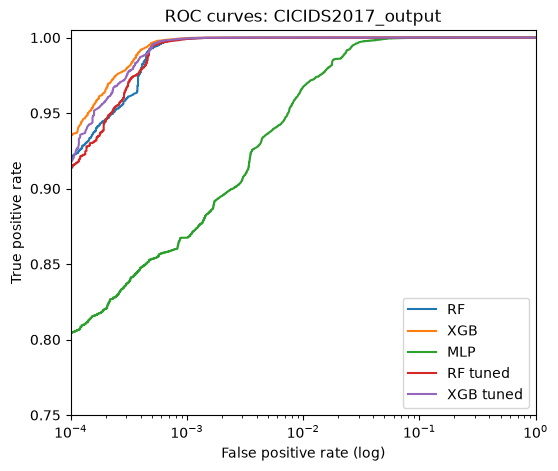

ROC curve figure successfully saved to ../figures/roc_CICIDS2017_output.png


In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

plt.figure(figsize=(6, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(yte, p)
    plt.plot(fpr, tpr, label=name)

plt.xscale('log')
plt.xlim(1e-4, 1)
plt.xlabel('False positive rate (log)')
plt.ylabel('True positive rate')
plt.legend()
plt.title('ROC curves: ' + DATASET)
plt.ylim(0.75, 1.005)
plt.savefig('../figures/roc_' + DATASET + '.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"ROC curve figure successfully saved to ../figures/roc_{DATASET}.png")

In [23]:
import json
json.dump({'rf': rf_s.best_params_, 'xgb': xgb_s.best_params_},
          open('../results/' + DATASET + '_best_params.json', 'w'), indent=2)

In [24]:
row, probs['RF tuned'] = evaluate('RF tuned', lambda X: best_rf.predict_proba(X)[:, 1], Xte, yte)
rows.append(row)
row, probs['XGB tuned'] = evaluate('XGB tuned', lambda X: best_xgb.predict_proba(X)[:, 1], Xte, yte)
rows.append(row)

res = pd.DataFrame(rows).round(4)
res.to_csv('../results/' + DATASET + '_models.csv', index=False)
display(res)

,model,accuracy,precision,recall,f1,roc_auc,fpr,fnr,infer_us,train_s
0,RF default,0.9991,0.9963,0.9982,0.9973,1.0000,0.0008,0.0018,1.3874,119.2705
1,XGB default,0.9991,0.9947,0.9998,0.9973,1.0000,0.0011,0.0002,0.3083,8.1127
2,MLP,0.9799,0.9031,0.9869,0.9431,0.9989,0.0215,0.0131,0.6941,NaN
3,RF tuned,0.9990,0.9948,0.9993,0.9971,1.0000,0.0011,0.0007,2.5485,NaN
4,XGB tuned,0.9990,0.9943,0.9998,0.9970,1.0000,0.0012,0.0002,0.5935,NaN


---

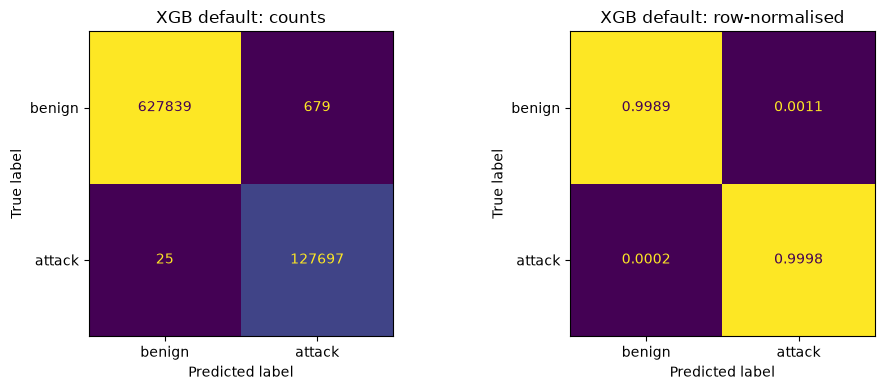

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

pred_c = (probs['XGB'] >= 0.5).astype(int)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(yte, pred_c, display_labels=['benign', 'attack'],
                                        values_format='d', ax=ax[0], colorbar=False)
ax[0].set_title('XGB default: counts')
ConfusionMatrixDisplay.from_predictions(yte, pred_c, display_labels=['benign', 'attack'],
                                        normalize='true', values_format='.4f', ax=ax[1], colorbar=False)
ax[1].set_title('XGB default: row-normalised')
plt.tight_layout()
plt.savefig('../figures/cm_xgb_' + DATASET + '.png', dpi=200, bbox_inches='tight'); plt.show()